In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

sns.set_theme(style="whitegrid", context="notebook")

# Load the Iris dataset
The dataset contains measurements for 150 flowers from three species:
- setosa
- versicolor
- virginica  

All measurements are in centimetres.

<img src="https://www.sciencefacts.net/wp-content/uploads/2021/12/Sepals.jpg" width="250">

In [ ]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
display(df.columns)

# rename to column names to be more readable
df.columns = [
    "sepal_length", "sepal_width",
    "petal_length", "petal_width", "species_code"
]

# replace target with actual names
df["species"] = iris.target_names[df["species_code"]]
display(df['species'])

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')

,species
0,setosa
1,setosa
2,setosa
3,setosa
4,setosa
...,...
145,virginica
146,virginica
147,virginica
148,virginica


In [ ]:
# Understand the dataframe
print(f"Shape: {df.shape}", end= "\n"+"-"*10+"\n")
print(f"Columns: {df.columns}", end= "\n"+"-"*10+"\n")
df.info()
print("-"*10+"\n")

# Missing values
print("Missing values:")
print(df.isna().sum())

Shape: (150, 6)
----------
Columns: Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species_code', 'species'],
      dtype='object')
----------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species_code  150 non-null    int64  
 5   species       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
----------

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species_code    0
species         0
dtype: int64


In [ ]:
print("Missing values:")
display(df.isna().sum().to_frame("missing_values"))

Missing values:


,missing_values
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species_code,0
species,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species_code  150 non-null    int64  
 5   species       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


# Univariate analysis

> **Study of 1 variable at a time**

Typical questions:
- What is a typical value?
- How spread out are the values?
- What is the shape of the distribution?
- Are there unusual or missing values?

## Part-1: One numerical variable: Sepal Length

In [ ]:
# list all the methods
df['sepal_length'].describe().__dir__()

# describe the variable
df["sepal_length"].describe()

,sepal_length
count,150.000000
mean,5.843333
std,0.828066
min,4.300000
25%,5.100000
50%,5.800000
75%,6.400000
max,7.900000


In [ ]:
# extract quantile values
# Approach-1
q1 = df["sepal_length"].describe()["25%"]
q3 = df["sepal_length"].describe()["75%"]
print(f"Q1: {q1:.2f}\nQ3: {q3:.2f}")

# Approach-2
Q1 = df["sepal_length"].quantile(0.25)
Q3 = df["sepal_length"].quantile(0.75)
IQR = Q3 - Q1
print(f"Q1: {Q1:.2f}\nQ3: {Q3:.2f}\nIQR: {IQR:.2f}")


Q1: 5.10
Q3: 6.40
Q1: 5.10
Q3: 6.40
IQR: 1.30


In [ ]:
# get basic statistics
print(f"Mean:   {df['sepal_length'].mean():.2f} cm")
print(f"Median: {df['sepal_length'].median():.2f} cm")
print(f"Range:  {df['sepal_length'].min():.1f} to {df['sepal_length'].max():.1f} cm")

Mean:   5.84 cm
Median: 5.80 cm
Range:  4.3 to 7.9 cm


#### A. Individual plots (in separate windows)

- Possible values of color:
  - "blue" (`#4C78A8`)
  - "red" (`#E45756`)
  - "green" (`#54A24B`)
  - "orange" (`#F2A65A`)
  - "purple" (`#B279A2`)
  - "darkorange" (`#F58518`)
  - "teal" (`#72B7B2`)

- `kde` = Kernel density estimation
  - adds a smooth curve over histogram to estimate the distribution of data



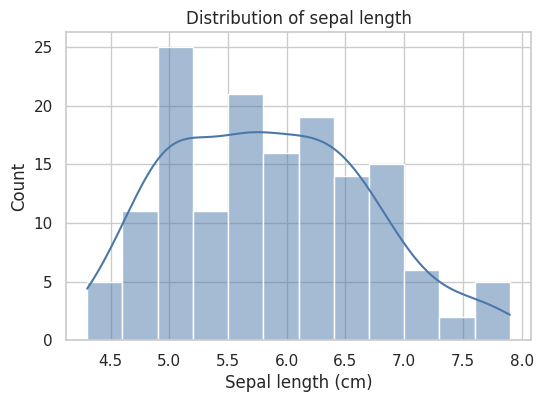

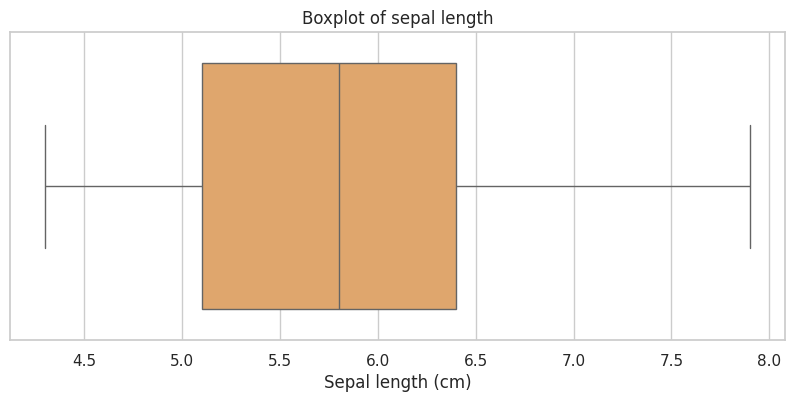

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns

plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="sepal_length", bins=12, kde=True, color="#4C78A8")
plt.title("Distribution of sepal length")
plt.xlabel("Sepal length (cm)")

plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="sepal_length", color="#F2A65A")
plt.title("Boxplot of sepal length")
plt.xlabel("Sepal length (cm)")

plt.show()

#### Pure `seaborn`
- Seaborn is built on Matplotlib, so both work together.
- Can you use only Seaborn? Yes, without explicitly importing Matplotlib.
- Use Seaborn for plotting and Matplotlib when you need more customization.

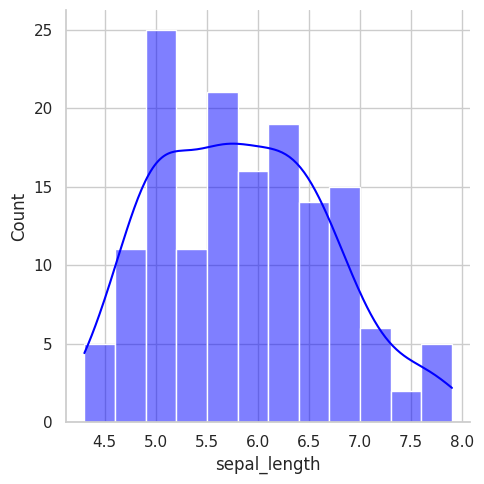

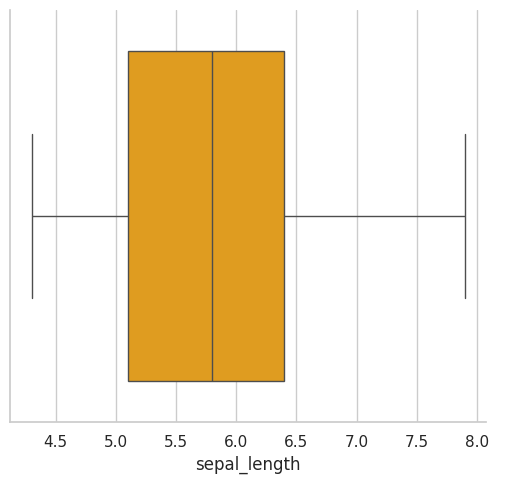

In [ ]:
# import seaborn as sns

# Histogram
sns.displot(data=df, x="sepal_length",
            bins=12, kde=True, color="blue")

# Boxplot
sns.catplot(data=df, x="sepal_length",
            kind="box", color="orange")

#### B. Combined plot (in single window)

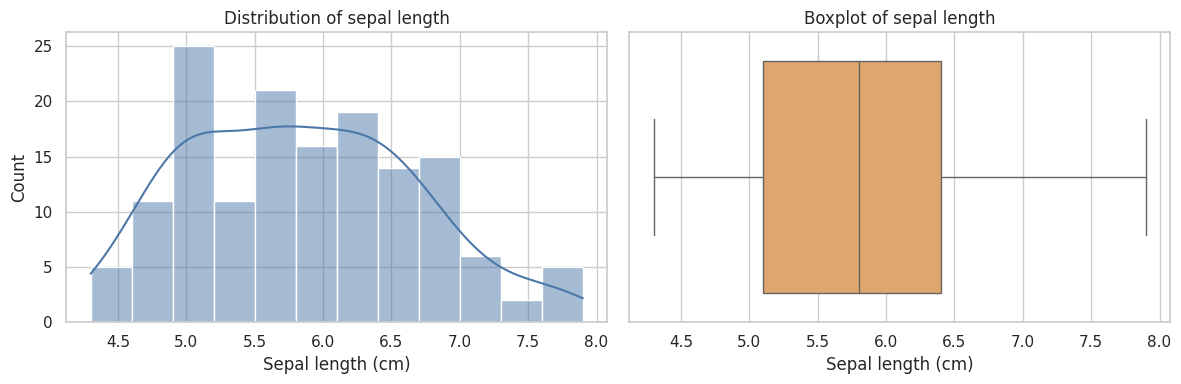

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="sepal_length", bins=12, kde=True, ax=axes[0], color="#4C78A8")
axes[0].set_title("Distribution of sepal length")
axes[0].set_xlabel("Sepal length (cm)")

sns.boxplot(data=df, x="sepal_length", ax=axes[1], color="#F2A65A")
axes[1].set_title("Boxplot of sepal length")
axes[1].set_xlabel("Sepal length (cm)")

plt.tight_layout()
plt.show()

## Part-2: One categorical variable: `species`

In [ ]:
species_summary = pd.DataFrame({
    "count": df["species"].value_counts(),
    "percentage": df["species"].value_counts(normalize=True).mul(100).round(1)
})

species_summary

,count,percentage
species,,
setosa,50,33.3
versicolor,50,33.3
virginica,50,33.3


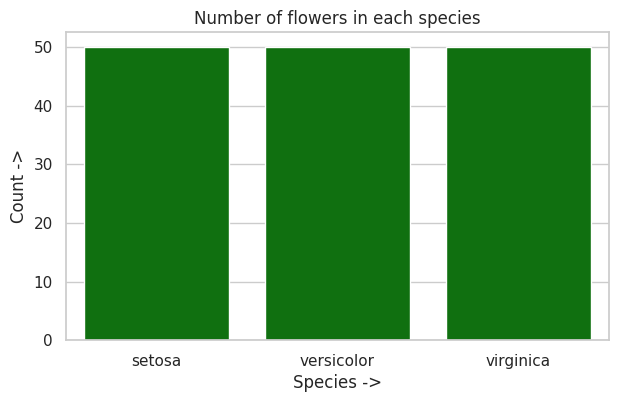

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="species", color="green")
plt.title("Number of flowers in each species")
plt.xlabel("Species ->")
plt.ylabel("Count ->")
plt.show()

# Bivariate analysis

| Variable combination | Useful summary | Useful plot |
|---|---|---|
| Numerical × numerical | Correlation | Scatterplot |
| Categorical × numerical | Grouped mean or median | Boxplot |
| Categorical × categorical | Crosstab and percentages | Stacked bar chart or heatmap |

## Part 1: Numerical x numerical

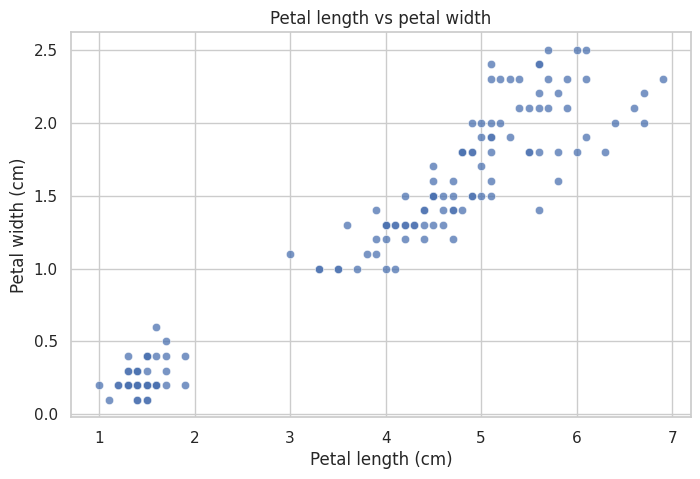

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="petal_length", y="petal_width", alpha=0.75)
plt.title("Petal length vs petal width")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.show()

In [ ]:
correlation = df["petal_length"].corr(df['petal_width'])
print(f"Correlation b/w petal 'length' and 'width': {correlation:.2f}")

Correlation b/w petal length and width: 0.96


In [ ]:
corr1 = df["petal_width"].corr(df['petal_length'])
print(f"Correlation b/w petal 'width' and 'length': {corr1:.2f}")

Correlation b/w petal 'width' and 'length': 0.96


In [ ]:
corr2 = df["sepal_length"].corr(df['sepal_width'])
print(f"Correlation b/w sepal length and width: {corr2:.2f}")

Correlation b/w sepal length and width: -0.12


#### Scatter plot between 2 flowers to show relation between sepal length and width

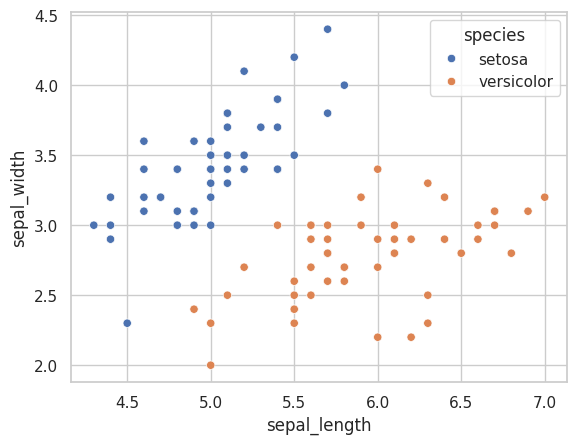

In [ ]:
df_two = df[df["species"].isin(["setosa", "versicolor"])]
# flower names: setosa, versicolor, virginica

sns.scatterplot(
    data=df_two,
    x="sepal_length",
    y="sepal_width",
    hue="species"
)

plt.show()

## Part 2: Categorical x numerical

Q: Does petal length differ across species?



In [ ]:
df.groupby("species")["petal_length"].agg(["count", "mean", "median", "min", "max"]).round(2)

,count,mean,median,min,max
species,,,,,
setosa,50,1.46,1.50,1.0,1.9
versicolor,50,4.26,4.35,3.0,5.1
virginica,50,5.55,5.55,4.5,6.9


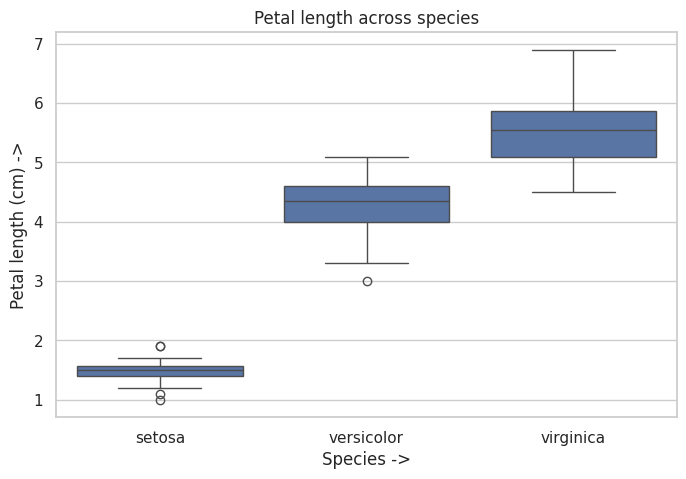

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="species", y="petal_length")
plt.title("Petal length across species")
plt.xlabel("Species ->")
plt.ylabel("Petal length (cm) ->")
plt.show()

## Part 3: Categorical x categorical

In [ ]:
df.groupby("species")["sepal_width"].agg(["count", "mean", "median", "min", "max"]).round(2)

,count,mean,median,min,max
species,,,,,
setosa,50,3.43,3.4,2.3,4.4
versicolor,50,2.77,2.8,2.0,3.4
virginica,50,2.97,3.0,2.2,3.8


In [ ]:
df["sepal_width_group"] = pd.cut(
    df["sepal_width"],
    bins=[0, 2.8, 3.2, float("inf")],
    labels=["narrow", "medium", "wide"]
)

df[["sepal_width", "sepal_width_group"]].head()

,sepal_width,sepal_width_group
0,3.5,wide
1,3.0,medium
2,3.2,medium
3,3.1,medium
4,3.6,wide


In [ ]:
width_by_species = (
    pd.crosstab(
        df["species"],
        df["sepal_width_group"],
        normalize="index"
    )
    .mul(100)
    .round(1)
)
width_by_species

sepal_width_group,narrow,medium,wide
species,,,
setosa,2.0,32.0,66.0
versicolor,54.0,42.0,4.0
virginica,38.0,46.0,16.0


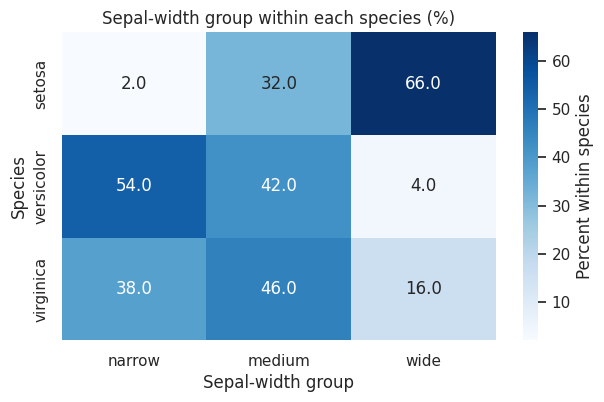

In [ ]:
plt.figure(figsize=(7, 4))
sns.heatmap(width_by_species, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Percent within species"})
plt.title("Sepal-width group within each species (%)")
plt.xlabel("Sepal-width group")
plt.ylabel("Species")
plt.show()